In [ ]:
from google.colab import files
import os

# Prompt to upload the dataset if it doesn't already exist
if not os.path.exists('/content/House_Price_dataset.csv'):
    print("Please upload your 'House_Price_dataset.csv' file:")
    uploaded = files.upload()
else:
    print("House_Price_dataset.csv already exists.")

House_Price_dataset.csv already exists.


In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv("/content/House_Price_dataset.csv")
df=df[df['purpose']=='For Sale'].copy()

In [ ]:
df = pd.read_csv('/content/House_Price_dataset.csv')


df = df[df['purpose'] == 'For Sale'].copy()

df['Area'] = df['Area Size']

df.loc[df['Area Type'] == 'Kanal', 'Area'] = df['Area Size'] * 20


df = df[(df['Area'] > 0) & (df['price'] > 0)]


df = df[
    (df['Area'] < df['Area'].quantile(0.99)) &
    (df['price'] < df['price'].quantile(0.99))
]


df = df.sample(n=2000, random_state=42).copy()


X = df[['Area', 'price']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

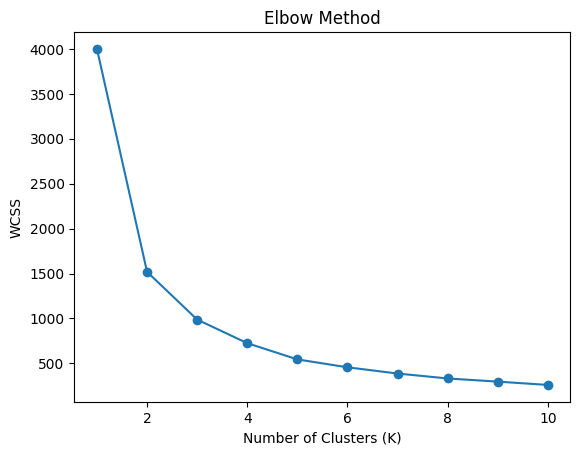

In [ ]:
wcss = []

for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print(df['Cluster'].value_counts().sort_index())

print(df.groupby('Cluster')[['Area', 'price']].mean())

Cluster
0      96
1    1125
2     248
3     531
Name: count, dtype: int64
              Area         price
Cluster                         
0        26.687500  1.085552e+08
1         4.596356  8.264826e+06
2        20.156452  4.616694e+07
3         9.873070  2.371282e+07


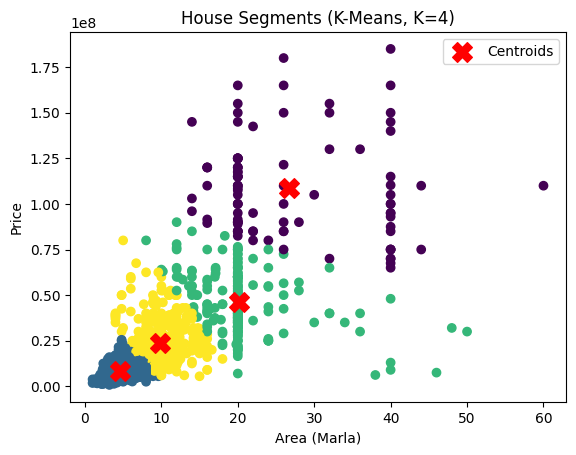

In [ ]:
plt.scatter(df['Area'], df['price'], c=df['Cluster'], cmap='viridis')
centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=200, label='Centroids')
plt.xlabel('Area (Marla)'); plt.ylabel('Price')
plt.title('House Segments (K-Means, K=4)'); plt.legend(); plt.show()